# [2, 2, 1] KAN symbolic regression with affine-domain mapping: field encoding (√m version)

$y = 0.3x_1^2 + \cos(3x_2)$ on $x \in [0, 1]$. Signed expansion coefficients, affine map on every layer.

**Field-encoding edge model** (update after IPC 2026). For an edge with $m$ photonic bases:

1. $u = \alpha x + \beta$ (affine map), or $u = x$ if no affine map is needed
2. $u/\sqrt{m}$ — 1:$m$ splitter
3. $P = u^2/m$ — optical power entering each FP-LD
4. $b_k(P)$ — analytic FP-LD activation (log/exp/polynomial fit)
5. $\sqrt{b_k(P)}$ — output field amplitude of basis $k$
6. $a_k \sqrt{b_k(P)}$ — expansion coefficient
7. $\varphi(x) = \sum_k a_k \sqrt{b_k(u^2/m)}$; edges are summed at the next node

The input range is chosen so that $P$ covers the same **power window** $[P_{\min}, P_{\max}]$ the bases saw in the May runs,
i.e. $u \in [\sqrt{m P_{\min}}, \sqrt{m P_{\max}}]$. Because every edge has the same $m$, the $1/\sqrt{m}$ factor is absorbed by this choice:
`DIVIDE_BY_M = False` gives identical results.

Here the affine map does the window mapping: $\alpha, \beta$ are chosen so that $u = \alpha x + \beta \in [\sqrt{m P_{\min}}, \sqrt{m P_{\max}}]$ over the layer's input range, hence $P = u^2/m \in [P_{\min}, P_{\max}]$.

## Imports

In [1]:
import os

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from scipy.io import savemat, loadmat

from importlib import reload
import kan
reload(kan)

from kan import KAN

## Settings

Only the photonic part differs from the May run (`affine_kan_2-2-1_consistent.ipynb`). Basis selection, data, input ranges, optimizer and epochs are unchanged. The power window is widened from [0.05, 2] to [0.05, 8] so that all selected bases switch inside it, and the learning rate decays exponentially from 1e-3 to 1e-4 (May: constant 1e-3).

In [2]:
# Photonic bases (same as May / IPC 2026)
selected_indices = [8, 10, 12, 14, 16, 18, 20, 22]
m = len(selected_indices)            # bases per edge

# Power window seen by the FP-LD: P = u^2/m in [P_MIN, P_MAX]
# May: [0.05, 2] (set empirically). The selected bases switch at P ~ 0.7 ... 7.5, so in [0.05, 2]
# most of them stay flat; the window is widened to 8 so that every selected basis switches inside it.
# Test runs (test MSE): P_MAX = 2 -> ~4.6e-4; P_MAX = 8 -> see the comparison at the end (May: 2.7e-5)
P_MIN, P_MAX = 0.05, 8.0
DIVIDE_BY_M = True                   # 1:m splitter; False gives identical results

# Input ranges of the affine maps, one entry per layer: [-input_neg_max, input_pos_max]
# Layer 0: same as May. Layer 1 (hidden node variables z): placeholder, set by the probe run below.
input_neg_max = [0.2, 3.0]
input_pos_max = [1.0, 3.0]

# Hidden-range calibration (training data only), based on estimate_hidden_ranges in kan_sparse_basis.py:
# 1. probe run: PROBE_EPOCHS epochs with a wide layer-1 range [-PROBE_RANGE, PROBE_RANGE];
#    measure the min and max hidden value z on the training inputs at the END of the probe
#    (the hidden range shrinks during training, so the extremes of early epochs are not representative)
# 2. layer-1 range = [z_min, z_max] widened by PROBE_MARGIN around its centre
# 3. full training run
# 4. check: u = alpha*z + beta >= 0 (no negative amplitude) and P = u^2/m <= P_FIT_MAX (fit range of the
#    activation) on the training inputs; leaving the window [P_MIN, P_MAX] slightly is allowed.
#    If the check fails: re-map layer 1 to the measured range x CALIB_MARGIN and retrain (max MAX_PASSES runs).
PROBE_EPOCHS = 1000
PROBE_RANGE = 10.0
PROBE_MARGIN = 1.10
CALIB_MARGIN = 1.10
MAX_PASSES = 10

SEED = 42
n_train = 1000
n_test = 300
x_min_test, x_max_test = 0.0, 1.0
num_epochs = 5000
lr = 1e-3                            # initial learning rate (as in May)
lr_final = 1e-4                      # learning rate at the last epoch: exponential decay lr -> lr_final.
                                     # May used a constant 1e-3; with it, Adam produced periodic loss spikes
                                     # (~10x, every ~400-500 epochs) once the loss was small.

mat_folder = "new_consistent_affine_2-2-1_sqrtm_exports"
os.makedirs(mat_folder, exist_ok=True)

u_lo, u_hi = kan.amplitude_window_from_power_window(P_MIN, P_MAX, m, DIVIDE_BY_M)
print(f"m = {m}")
print(f"Power window P = [{P_MIN}, {P_MAX}]  ->  amplitude window u = alpha*x + beta in [{u_lo:.6f}, {u_hi:.6f}]")

m = 8
Power window P = [0.05, 8.0]  ->  amplitude window u = alpha*x + beta in [0.632456, 8.000000]


## Load photonic activation

In [3]:
mat_path = "activation_KAN_fit_B_Sofija_extend_positive_basisKAN.mat"

b_coef, input_power, peakout_data, set_detuning = kan.load_photonic_activation_data(mat_path)
b_coef_selected = b_coef[selected_indices]

print("Selected indices:", selected_indices)
print("Selected detunings:", set_detuning[selected_indices])
print("Selected b_coef shape:", b_coef_selected.shape)

P_FIT_MAX = float(input_power.max())   # upper end of the input-power range the activation was fitted on
print("Activation fit range: P in [0,", P_FIT_MAX, "]")

Selected indices: [8, 10, 12, 14, 16, 18, 20, 22]
Selected detunings: tensor([-1.3000e+11, -1.5000e+11, -1.7000e+11, -1.9000e+11, -2.1000e+11,
        -2.3000e+11, -2.5000e+11, -2.7000e+11])
Selected b_coef shape: torch.Size([8, 8])
Activation fit range: P in [0, 60.0 ]


## Data (same as May)

In [4]:
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

x_train = x_min_test + (x_max_test - x_min_test) * torch.rand(n_train, 2)
x_test = x_min_test + (x_max_test - x_min_test) * torch.rand(n_test, 2)

def target_fn(x):
    x1 = x[:, 0:1]
    x2 = x[:, 1:2]
    return 0.3 * x1**2 + torch.cos(3.0 * x2)

y_train = target_fn(x_train)
y_test = target_fn(x_test)

# RNG state after the data, as in May (model initialised right after the data); restored in every pass
rng_state_after_data = torch.get_rng_state()

x_train = x_train.to(device=device, dtype=torch.float64)
y_train = y_train.to(device=device, dtype=torch.float64)
x_test = x_test.to(device=device, dtype=torch.float64)
y_test = y_test.to(device=device, dtype=torch.float64)

## Model and training helpers

In [5]:
def build_model(layer1_range=None, margin=1.0):
    # Same initialisation as May, and the same in every calibration pass
    torch.set_rng_state(rng_state_after_data)
    model = KAN(
        in_count=2,
        out_count=1,
        hidden_layer_sizes=[2],
        layer_type="photonic_interval_affine_clean",
        b_coef_selected=b_coef_selected,
        input_neg_max=input_neg_max,
        input_pos_max=input_pos_max,
        basis_min=P_MIN,               # with field encoding: power window
        basis_max=P_MAX,
        dropout_prob=0.0,
        debug=False,
        field_encoding=True,
        divide_by_m=DIVIDE_BY_M,
    ).to(device=device, dtype=torch.float64)

    if layer1_range is not None:
        model.layers[1].set_input_range(*layer1_range, margin=margin)
    return model


def train_model(model, num_epochs, lr, lr_final, log_every=500):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    # multiply the learning rate by gamma after every epoch, so it reaches lr_final at the last epoch
    gamma = (lr_final / lr) ** (1.0 / max(num_epochs - 1, 1))
    scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=gamma)
    loss_fn = nn.MSELoss()
    train_losses, test_losses, lrs = [], [], []

    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()
        loss = loss_fn(model(x_train), y_train)
        loss.backward()
        optimizer.step()
        lrs.append(optimizer.param_groups[0]["lr"])
        scheduler.step()

        model.eval()
        with torch.no_grad():
            test_loss = loss_fn(model(x_test), y_test)

        train_losses.append(loss.item())
        test_losses.append(test_loss.item())

        if epoch % log_every == 0 or epoch == num_epochs - 1:
            print(f"Epoch {epoch:5d} | lr = {lrs[-1]:.2e} | train loss = {loss.item():.8f} | test loss = {test_loss.item():.8f}")

    return train_losses, test_losses, lrs


def hidden_range(model, x):
    # min and max hidden value z for inputs x
    model.eval()
    with torch.no_grad():
        _, acts = model(x, return_all=True)
    z = acts[1]
    return z.min().item(), z.max().item()


def layer1_validity(model, x):
    # min of u = alpha*z + beta and max of P = u^2/m in layer 1, for inputs x
    model.eval()
    with torch.no_grad():
        _, stats = model(x, track_stats=True)
    s = stats[1]
    return s["min_affine_input"].item(), s["max_P"].item()


def probe_hidden_range(probe_epochs, probe_range):
    # Short probe run with a wide layer-1 range (constant learning rate, as in estimate_hidden_ranges);
    # returns the min / max hidden value on the training inputs at the end of the probe.
    probe = build_model((-probe_range, probe_range))
    optimizer = optim.Adam(probe.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    for epoch in range(probe_epochs):
        probe.train()
        optimizer.zero_grad()
        loss = loss_fn(probe(x_train), y_train)
        loss.backward()
        optimizer.step()
    z_lo, z_hi = hidden_range(probe, x_train)
    print(f"Probe ({probe_epochs} epochs, layer-1 range +-{probe_range}): hidden z in [{z_lo:.4f}, {z_hi:.4f}], "
          f"train loss {loss.item():.3e}")
    return z_lo, z_hi

## Hidden-range calibration and training

Only training data are used to set the layer-1 mapping.

1. **Probe run:** `PROBE_EPOCHS` = 1000 epochs with a wide layer-1 range $[-10, 10]$; the min and max hidden value $z$ on the training inputs are measured at the end of the probe (based on `estimate_hidden_ranges` in `kan_sparse_basis.py`, which used 200 epochs, the extremes over all probe epochs and $\pm\max|z|$; the hidden range shrinks during training, so the end of a longer probe is more representative).
2. **Layer-1 range** = $[z_{\min}, z_{\max}]$ widened by `PROBE_MARGIN`; $\alpha, \beta$ of layer 1 follow from it.
3. **Full training run.**
4. **Check** on the training inputs: $u = \alpha z + \beta \ge 0$ (no negative amplitude) and $P = u^2/m \le$ `P_FIT_MAX` (fit range of the activation). Leaving the window $[P_{\min}, P_{\max}]$ slightly is allowed. If the check fails, layer 1 is re-mapped to the measured range × `CALIB_MARGIN` and the model is retrained from the same initialisation.

The same check on the test inputs is only reported.

In [6]:
z_probe_min, z_probe_max = probe_hidden_range(PROBE_EPOCHS, PROBE_RANGE)

layer1_range, margin = (z_probe_min, z_probe_max), PROBE_MARGIN
calibration_log = []

for p in range(MAX_PASSES):
    model = build_model(layer1_range, margin)
    L1 = model.layers[1]
    print(f"\n=== Run {p + 1}: layer-1 input range [{L1.input_min:.4f}, {L1.input_max:.4f}] "
          f"(alpha = {L1.alpha[0].item():.4f}, beta = {L1.beta[0].item():.4f}) ===")

    train_losses, test_losses, lrs = train_model(model, num_epochs, lr, lr_final)

    z_min, z_max = hidden_range(model, x_train)
    u_min, P_max_obs = layer1_validity(model, x_train)
    valid = (u_min >= 0.0) and (P_max_obs <= P_FIT_MAX)
    calibration_log.append([p + 1, L1.input_min, L1.input_max, z_min, z_max, u_min, P_max_obs, test_losses[-1]])
    print(f"Hidden range (train) after training: [{z_min:.4f}, {z_max:.4f}] | layer-1 min u = {u_min:.4f} (must be >= 0), "
          f"max P = {P_max_obs:.3f} (must be <= {P_FIT_MAX:g}) -> {'VALID' if valid else 'INVALID, re-mapping layer 1'}")

    if valid:
        break
    layer1_range, margin = (z_min, z_max), CALIB_MARGIN
else:
    print("\nWARNING: layer 1 still not physically valid after MAX_PASSES runs.")

calibration_log = np.array(calibration_log)

# Report only: the same check on the test inputs
u_min_test, P_max_test = layer1_validity(model, x_test)
test_valid = (u_min_test >= 0.0) and (P_max_test <= P_FIT_MAX)
print(f"\nTest inputs: layer-1 min u = {u_min_test:.4f}, max P = {P_max_test:.3f} -> "
      f"{'valid' if test_valid else 'WARNING: test inputs leave the valid range'}")

Probe (1000 epochs, layer-1 range +-10.0): hidden z in [-6.8900, 2.6047], train loss 4.876e-04

=== Run 1: layer-1 input range [-7.3647, 3.0795] (alpha = 0.7054, beta = 5.8277) ===
Epoch     0 | lr = 1.00e-03 | train loss = 0.49068344 | test loss = 0.48149268
Epoch   500 | lr = 7.94e-04 | train loss = 0.00476838 | test loss = 0.00411102
Epoch  1000 | lr = 6.31e-04 | train loss = 0.00078600 | test loss = 0.00058096
Epoch  1500 | lr = 5.01e-04 | train loss = 0.00030890 | test loss = 0.00022213
Epoch  2000 | lr = 3.98e-04 | train loss = 0.00016350 | test loss = 0.00012133
Epoch  2500 | lr = 3.16e-04 | train loss = 0.00009801 | test loss = 0.00007668
Epoch  3000 | lr = 2.51e-04 | train loss = 0.00006618 | test loss = 0.00005538
Epoch  3500 | lr = 1.99e-04 | train loss = 0.00004999 | test loss = 0.00004465
Epoch  4000 | lr = 1.58e-04 | train loss = 0.00004127 | test loss = 0.00003884
Epoch  4500 | lr = 1.26e-04 | train loss = 0.00003630 | test loss = 0.00003545
Epoch  4999 | lr = 1.00e-04 |

## Final MSE and photonic ranges

In [7]:
model.eval()
with torch.no_grad():
    y_pred_train = model(x_train)
    y_pred_test = model(x_test)
    _, stats = model(torch.cat([x_train, x_test]), track_stats=True)

train_mse = nn.functional.mse_loss(y_pred_train, y_train).item()
test_mse = nn.functional.mse_loss(y_pred_test, y_test).item()
print(f"Final train MSE: {train_mse:.4e}")
print(f"Final test MSE:  {test_mse:.4e}\n")

for s in stats:
    print(f"Layer {s['layer']}: input [{s['min_input'].item():.4f}, {s['max_input'].item():.4f}] | "
          f"u [{s['min_affine_input'].item():.4f}, {s['max_affine_input'].item():.4f}] | "
          f"P [{s['min_P'].item():.4f}, {s['max_P'].item():.4f}] | "
          f"outside window: {100 * s['frac_outside_window'].item():.2f} %")

print()
model.print_photonic_affine_params()

Final train MSE: 3.3315e-05
Final test MSE:  3.3341e-05

Layer 0: input [0.0023, 0.9998] | u [1.8748, 7.9988] | P [0.4394, 7.9976] | outside window: 0.00 %
Layer 1: input [-3.0997, 0.8184] | u [3.6411, 6.4050] | P [1.6572, 5.1280] | outside window: 0.00 %

Photonic interval affine parameters:

Layer 0: PhotonicBasisActivationLayerIntervalAffineClean
  in_count = 2
  out_count = 2
  input_neg_max = 0.2
  input_pos_max = 1.0
  field encoding: edge = sum_k a_k sqrt(b_k(u^2/m)), m = 8, divide_by_m = True
  power window P = [0.05, 8.0]
  amplitude window u = alpha*x+beta in [0.632456, 8]
  alpha shape = (2,)
  beta shape  = (2,)
  alpha values = [6.1396203 6.1396203]
  beta values  = [1.86037958 1.86037958]
  alpha unique = [6.1396203]
  beta unique  = [1.86037958]

Layer 1: PhotonicBasisActivationLayerIntervalAffineClean
  in_count = 2
  out_count = 1
  input_neg_max = 7.36471654248812
  input_pos_max = 3.0794556744349997
  field encoding: edge = sum_k a_k sqrt(b_k(u^2/m)), m = 8, divide_b

## Loss curves and true vs predicted

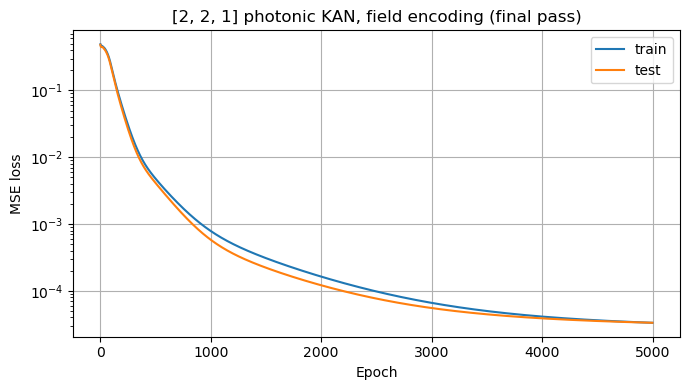

In [8]:
savemat(os.path.join(mat_folder, "loss_curves.mat"), {
    "plot_type": "loss_curves",
    "epoch": np.arange(num_epochs),
    "train_losses": np.array(train_losses),
    "test_losses": np.array(test_losses),
    "num_epochs": num_epochs,
    "learning_rate": np.array(lrs),       # learning rate used at each epoch
    "calibration_log": calibration_log,   # [pass, layer1_in_min, layer1_in_max, z_min, z_max, u_min, P_max, final_test_loss]
})

plt.figure(figsize=(7, 4))
plt.semilogy(train_losses, label="train")
plt.semilogy(test_losses, label="test")
plt.xlabel("Epoch"); plt.ylabel("MSE loss")
plt.title("[2, 2, 1] photonic KAN, field encoding (final pass)")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

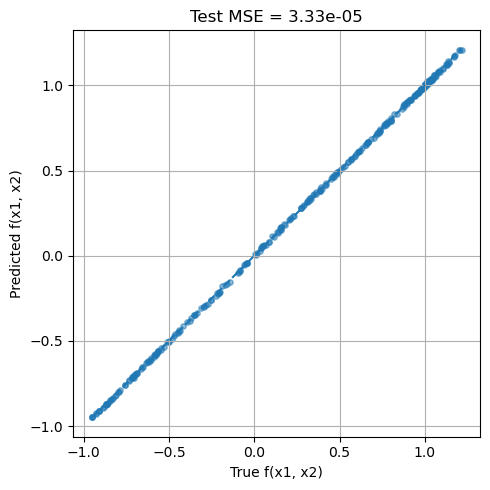

In [9]:
savemat(os.path.join(mat_folder, "true_vs_pred_test.mat"), {
    "plot_type": "true_vs_pred_test",
    "x_test": x_test.detach().cpu().numpy(),
    "y_test": y_test.detach().cpu().numpy(),
    "y_pred_test": y_pred_test.detach().cpu().numpy(),
    "test_mse": test_mse,
})

plt.figure(figsize=(5, 5))
yt = y_test.cpu().numpy(); yp = y_pred_test.cpu().numpy()
plt.scatter(yt, yp, alpha=0.5, s=15)
lo, hi = min(yt.min(), yp.min()), max(yt.max(), yp.max())
plt.plot([lo, hi], [lo, hi], linestyle="--")
plt.xlabel("True f(x1, x2)"); plt.ylabel("Predicted f(x1, x2)")
plt.title(f"Test MSE = {test_mse:.2e}")
plt.grid(True); plt.tight_layout(); plt.show()

## Basis functions, edge functions, coefficient vectors

Layer 0 is plotted over $x \in [0, 1]$, layer 1 over the observed hidden range. The basis is the effective basis $\sqrt{b_k((\alpha x+\beta)^2/m)}$; `.mat` files also contain `u`, `P` and `b_raw`.

hidden min: -3.099743673390808  hidden max: 0.8183943895256071
Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/basis_functions_L0_in0.mat


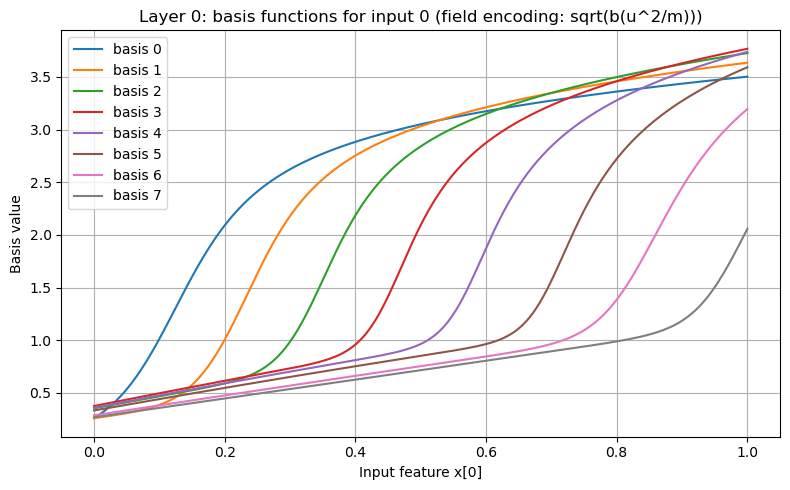

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/basis_functions_L0_in1.mat


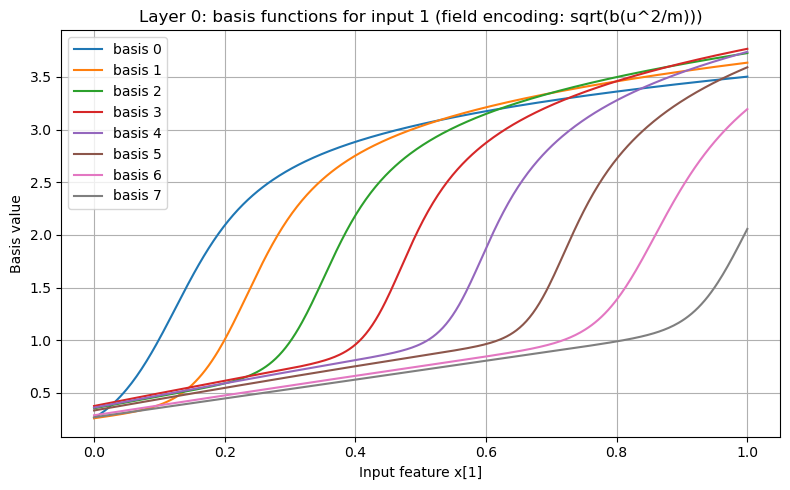

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/basis_functions_L1_in0.mat


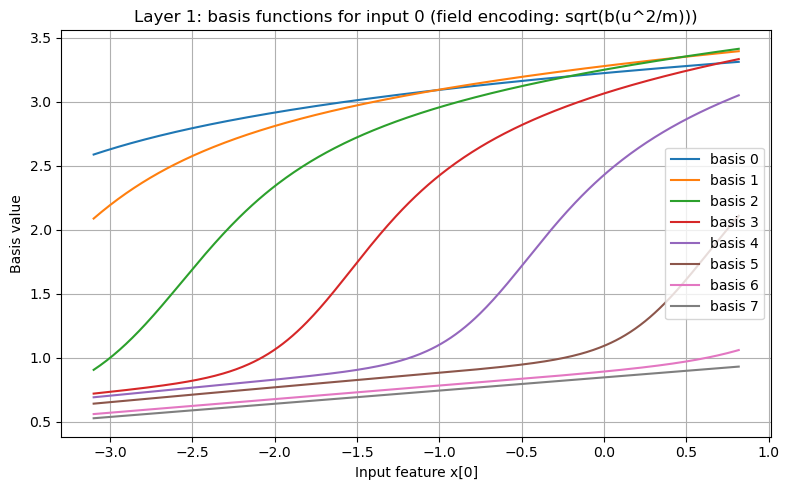

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/basis_functions_L1_in1.mat


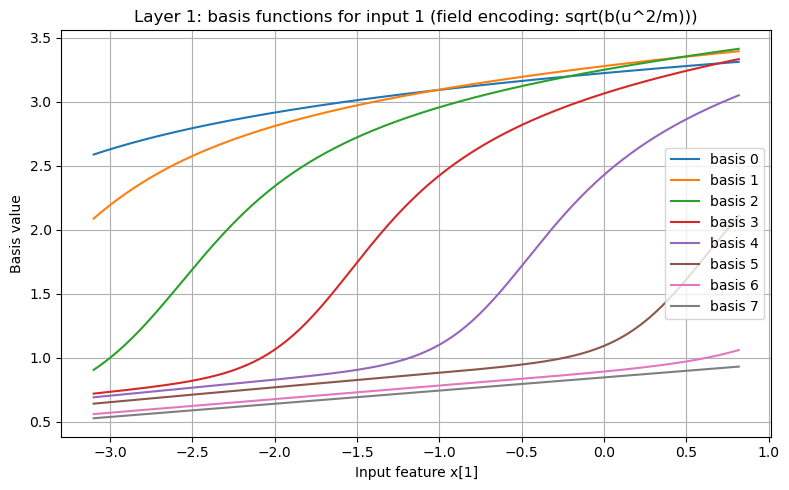

basis shape: torch.Size([400, 8])
basis finite: True
phi finite: True
Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/edge_function_L0_out0_in0.mat


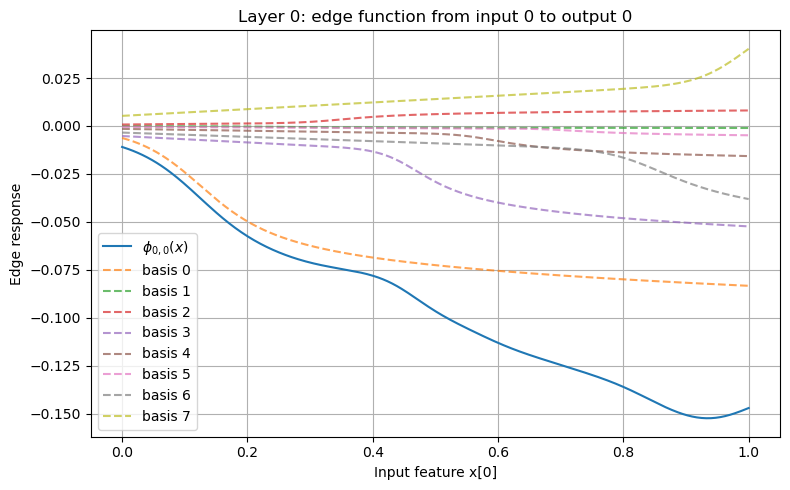

basis shape: torch.Size([400, 8])
basis finite: True
phi finite: True
Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/edge_function_L0_out0_in1.mat


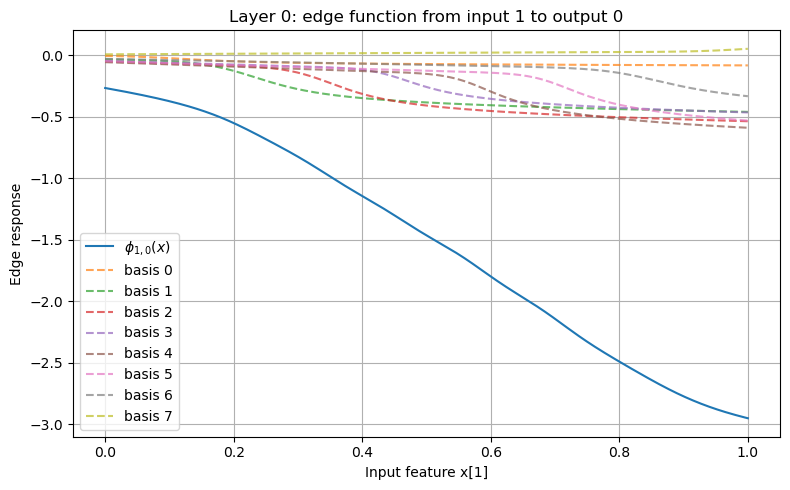

basis shape: torch.Size([400, 8])
basis finite: True
phi finite: True
Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/edge_function_L0_out1_in0.mat


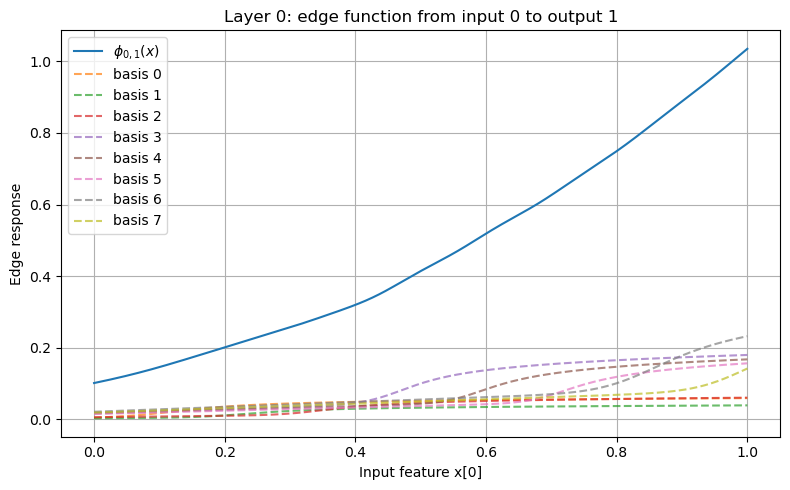

basis shape: torch.Size([400, 8])
basis finite: True
phi finite: True
Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/edge_function_L0_out1_in1.mat


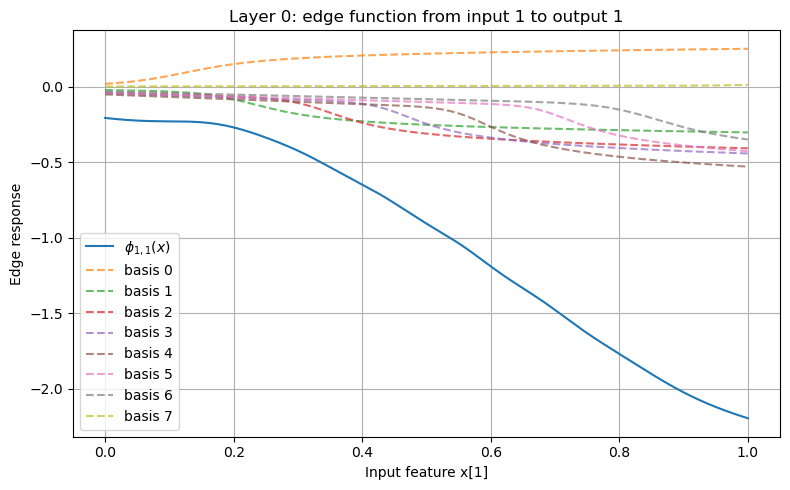

basis shape: torch.Size([400, 8])
basis finite: True
phi finite: True
Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/edge_function_L1_out0_in0.mat


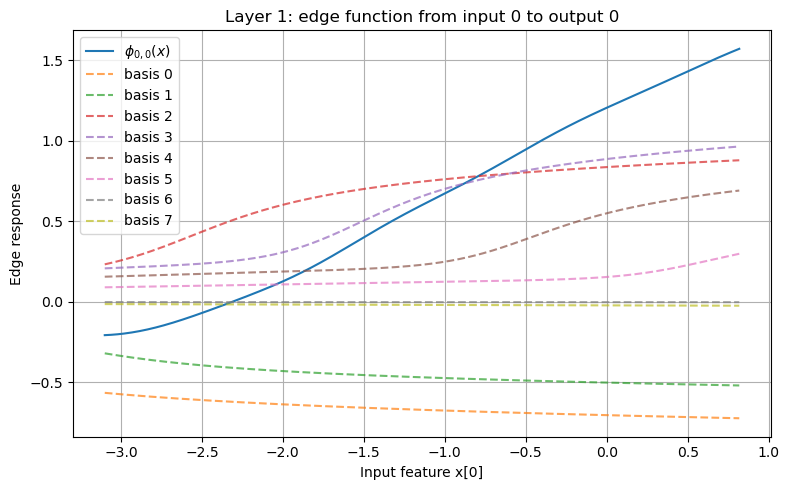

basis shape: torch.Size([400, 8])
basis finite: True
phi finite: True
Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/edge_function_L1_out0_in1.mat


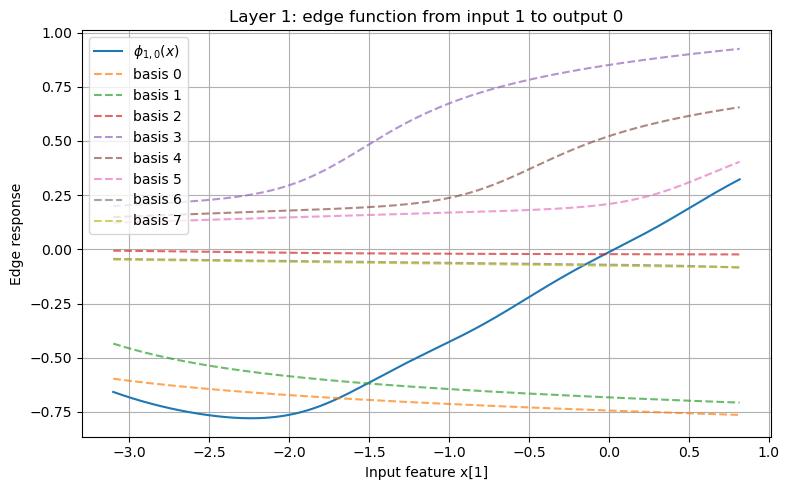

In [10]:
z_min, z_max = hidden_range(model, torch.cat([x_train, x_test]))   # plotting range only
print("hidden min:", z_min, " hidden max:", z_max)

for in_idx in range(2):
    model.plot_basis_functions(layer_idx=0, in_idx=in_idx, x_range=(x_min_test, x_max_test),
                               mat_export_path=f"basis_functions_L0_in{in_idx}.mat", mat_export_dir=mat_folder)
for in_idx in range(2):
    model.plot_basis_functions(layer_idx=1, in_idx=in_idx, x_range=(z_min, z_max),
                               mat_export_path=f"basis_functions_L1_in{in_idx}.mat", mat_export_dir=mat_folder)

for out_idx in range(2):
    for in_idx in range(2):
        model.plot_edge_function(layer_idx=0, out_idx=out_idx, in_idx=in_idx, x_range=(x_min_test, x_max_test),
                                 show_basis=True, mat_export_path=f"edge_function_L0_out{out_idx}_in{in_idx}.mat",
                                 mat_export_dir=mat_folder)
for in_idx in range(2):
    model.plot_edge_function(layer_idx=1, out_idx=0, in_idx=in_idx, x_range=(z_min, z_max),
                             show_basis=True, mat_export_path=f"edge_function_L1_out0_in{in_idx}.mat",
                             mat_export_dir=mat_folder)

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/coefficient_vector_L0_out0_in0.mat


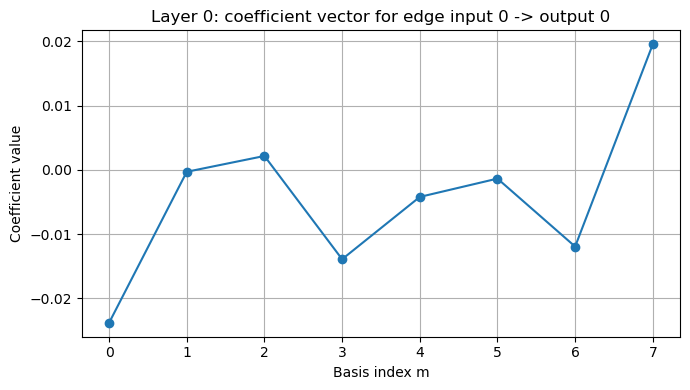

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/coefficient_vector_L0_out0_in1.mat


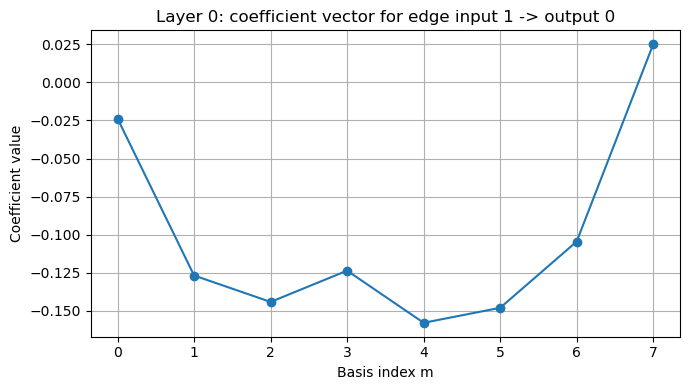

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/coefficient_vector_L0_out1_in0.mat


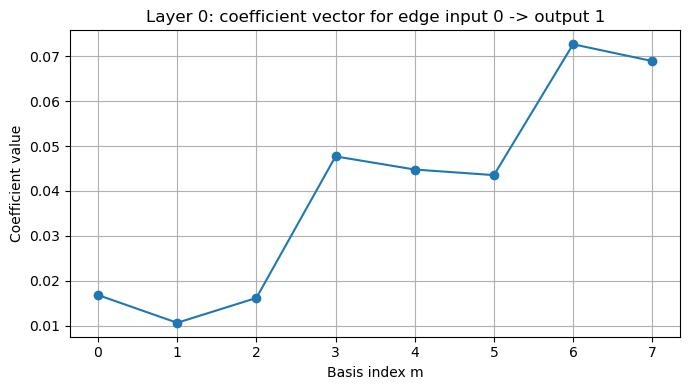

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/coefficient_vector_L0_out1_in1.mat


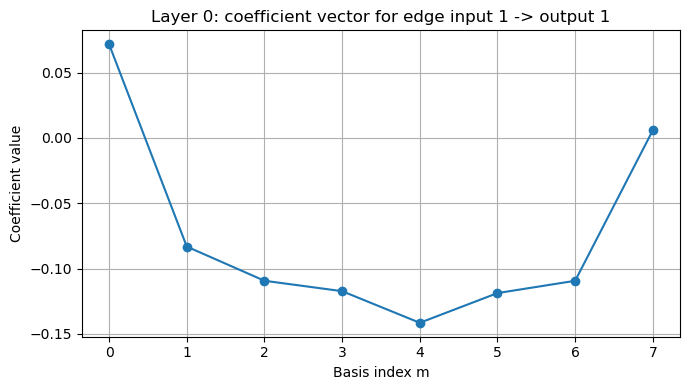

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/coefficient_vector_L1_out0_in0.mat


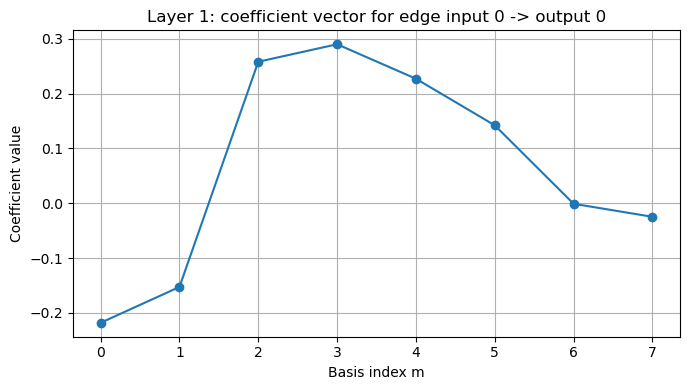

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/coefficient_vector_L1_out0_in1.mat


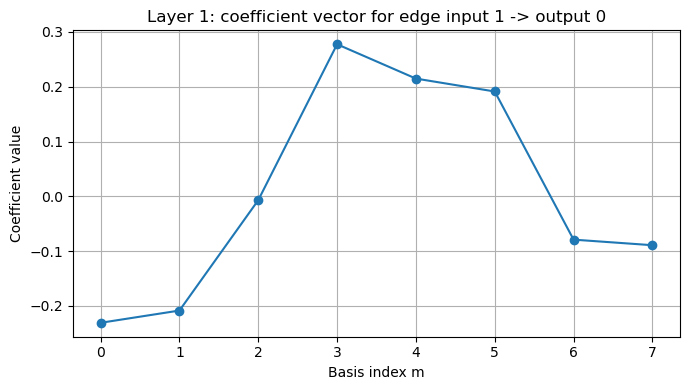

In [11]:
for out_idx in range(2):
    for in_idx in range(2):
        model.plot_coefficient_vector(layer_idx=0, out_idx=out_idx, in_idx=in_idx,
                                      mat_export_path=f"coefficient_vector_L0_out{out_idx}_in{in_idx}.mat",
                                      mat_export_dir=mat_folder)
for in_idx in range(2):
    model.plot_coefficient_vector(layer_idx=1, out_idx=0, in_idx=in_idx,
                                  mat_export_path=f"coefficient_vector_L1_out0_in{in_idx}.mat",
                                  mat_export_dir=mat_folder)

## Target approximation along one input

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/target_approximation_0.5_varied_x0.mat


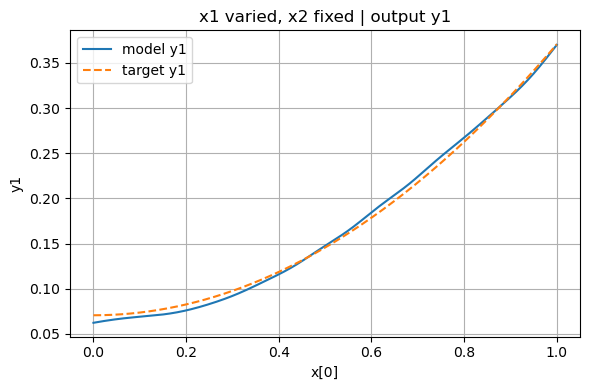

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/target_approximation_0.5_varied_x1.mat


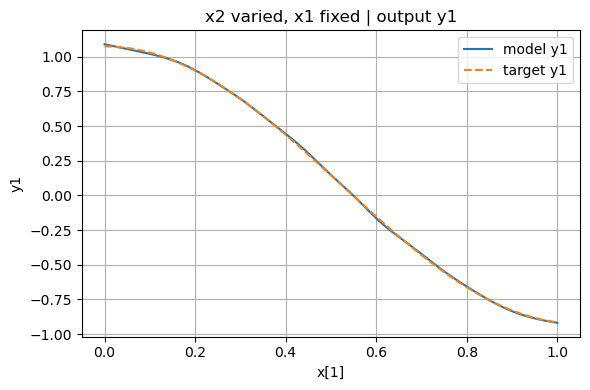

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/target_approximation_0.0_varied_x0.mat


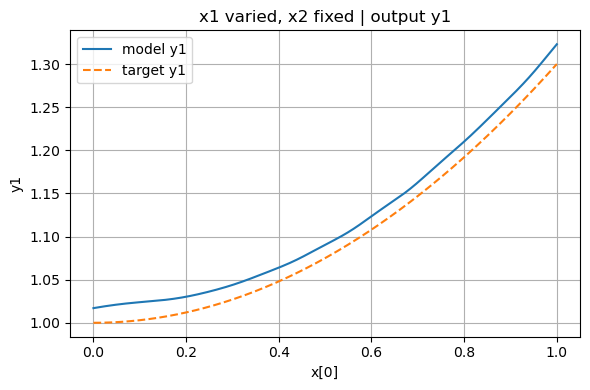

Saved MATLAB plot data to: new_consistent_affine_2-2-1_sqrtm_exports/target_approximation_0.0_varied_x1.mat


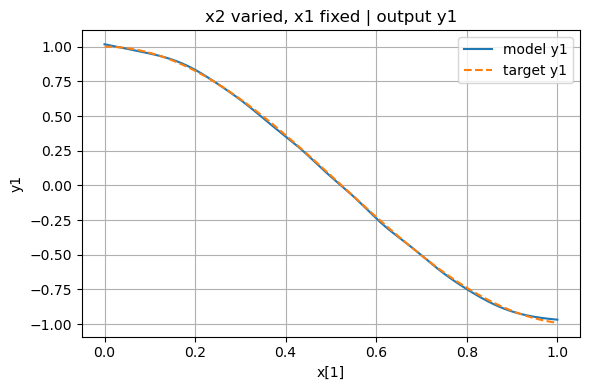

In [12]:
for fixed, prefix in [(0.5, "target_approximation_0.5"), (0.0, "target_approximation_0.0")]:
    model.plot_target_approximation(
        target_fn=target_fn,
        x_range=(x_min_test, x_max_test),
        fixed_values=[fixed, fixed],
        resolution=400,
        mat_export_prefix=prefix,
        mat_export_dir=mat_folder,
    )

## Full forward pass export (MATLAB) and independent NumPy check

In [13]:
extra = {
    "model_description": "[2,2,1] photonic KAN with affine mapping, field encoding: edge = sum_k a_k sqrt(b_k((alpha*x+beta)^2/m))",
    "target": "y = 0.3*x1^2 + cos(3*x2)",
    "power_window": np.array([P_MIN, P_MAX]),
    "selected_indices_python": np.array(selected_indices),
    "selected_indices_matlab": np.array(selected_indices) + 1,
    "selected_detunings": set_detuning[selected_indices],
    "x_test": x_test, "y_test": y_test, "y_pred_test": y_pred_test,
    "train_mse": train_mse, "test_mse": test_mse,
    "calibration_log": calibration_log, "calib_margin": CALIB_MARGIN,
    "probe_epochs": PROBE_EPOCHS, "probe_range": PROBE_RANGE, "probe_margin": PROBE_MARGIN,
    "probe_hidden_range": np.array([z_probe_min, z_probe_max]),
    "hidden_range_observed": np.array([z_min, z_max]),
    "seed": SEED, "num_epochs": num_epochs, "lr": lr, "lr_final": lr_final,
}

err = kan.export_full_forward_to_mat(
    model, x_test,
    os.path.join(mat_folder, "photonic_kan_2-2-1_sqrtm_full_forward_test.mat"),
    extra=extra,
)
assert err < 1e-8, "PyTorch and NumPy forward passes disagree"

Saved full forward pass to: new_consistent_affine_2-2-1_sqrtm_exports/photonic_kan_2-2-1_sqrtm_full_forward_test.mat
Max |PyTorch - NumPy| = 1.166e-15  (relative to max |y|: 9.628e-16)


## Comparison with the May (IPC 2026) result

In [14]:
old_path = os.path.join("results_v1_IPC2026", "new_consistent_affine_2-2-1_exports", "true_vs_pred_test.mat")
if os.path.exists(old_path):
    old = loadmat(old_path, squeeze_me=True)
    old_mse = float(((old["y_pred_test"] - old["y_test"]) ** 2).mean())
else:
    old_mse = 2.7e-5  # value reported in the abstract

print(f"{'':12s}{'May (b(u))':>14s}{'new (sqrt(b(u^2/m)))':>24s}")
print(f"{'Test MSE':12s}{old_mse:>14.3e}{test_mse:>24.3e}")

                May (b(u))    new (sqrt(b(u^2/m)))
Test MSE         2.722e-05               3.334e-05
